<a href="https://colab.research.google.com/github/XanderPatterson/4487-IS-Class-Labs/blob/main/assignment_13_text_analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 13 Text Analytics

In this assignment, you will:
- Load and inspect a real-world business reviews dataset.
- Preprocess review text for NLP (tokenization, stopwords, lemmatization).
- Run sentiment analysis (rule-based and classifier-based) and compare to star ratings.
- Extract main topics from reviews using LDA and (optional) BERTopic.
- Interpret results in a business context (actionable insights).

## Why This Matters

Customer Reviews are critical for the survival of any business, but especially for restaurants.  Restaurants compete with not only all of the other restaurants in local area, but also with the option for customers to stay home and cook their own food.  Chefs and restaurant owners must monitor customer feedback to see if they should make changes to their pricing, menu options, restaurant amenities and seating/serving process.

You have been given 100 customer reviews.  Your job is to look for main topics that are mentioned, and whether those reviews have a postive, neutral or negative tone (sentiment).  

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_13_text_analytics.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Original Source: Dataset Description

The dataset you'll be using is a set of **restaurant reviews**, available from [Kaggle](https://www.kaggle.com/datasets/pruthvirajgshitole/e-commerce-purchases-and-reviews?utm_source=chatgpt.com&select=customer_purchase_data.csv).

Each row represents one customer review. The columns include:

- **Review** - text of the customer review
- **Liked** - indicates if the customer likes (1) or does not like (0) the restaurant

Please note that some reviews have commas and apostrophes, which can prevent the record from loading correctly.  You should verify that you have 1,000 reviews total.  

## 1. Load and Preview the Data

### Do the following:
1. Import data from the restaurant reviews dataset into a dataframe (in GitHub go to the DataSets folder and look for `Restaurant_Reviews.tsv`).  TSV is for Tab Separated Values.  This file does not use commas as a delimiter.
2. Use `pandas` to load and preview the dataset
3. Verify that all 1,000 rows were imported correctly
4. Calculate the overall percentage of reviews that "Liked" the restaurant
5. Create a visualization to show the percentage of likes versus non-likes


In [23]:
import pandas as pd
import csv

# Load the reviews
url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/refs/heads/main/DataSets/Restaurant_Reviews.tsv"
df = pd.read_csv(url, sep='\t', quoting=csv.QUOTE_MINIMAL)

df.head()

,Review,Liked
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1


Percentage of Liked reviews: 50.0%


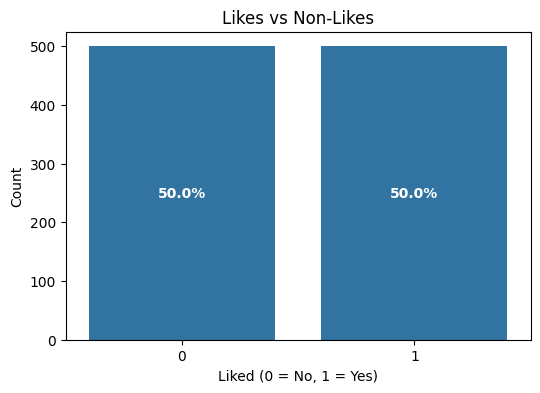

In [24]:
import pandas as pd
import csv
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/refs/heads/main/DataSets/Restaurant_Reviews.tsv"
df = pd.read_csv(url, sep='\t', quoting=csv.QUOTE_MINIMAL)
like_percentage = df['Liked'].mean() * 100
print(f"Percentage of Liked reviews: {like_percentage:.1f}%")

plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Liked', data=df)

total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold')

plt.title('Likes vs Non-Likes')
plt.xlabel('Liked (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

## 2. Drop Columns Not Useful for Modeling

**Business framing:**  
To do text analysis, we need to remove all of the junk in the reviews.  This would include anything like punctuation, website URLs, emojis, etc.

### Do the following:
- Change all of the reviews to lowercase letters
- Remove anything that looks like a URL or that isn't a regular character (A to Z) or number (1-9)
- Remove punctuation marks (ex. !.,-:;)

In [25]:
import re

cleaned_reviews = []

for text in df['Review']:
    text = text.lower()
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'[^a-z0-9\s]', '', text)
    text = ' '.join(text.split())
    cleaned_reviews.append(text)

df['Cleaned_Review'] = cleaned_reviews

df[['Review', 'Cleaned_Review']].head(15)

,Review,Cleaned_Review
0,Wow... Loved this place.,wow loved this place
1,Crust is not good.,crust is not good
2,Not tasty and the texture was just nasty.,not tasty and the texture was just nasty
3,Stopped by during the late May bank holiday of...,stopped by during the late may bank holiday of...
4,The selection on the menu was great and so wer...,the selection on the menu was great and so wer...
5,Now I am getting angry and I want my damn pho.,now i am getting angry and i want my damn pho
6,Honeslty it didn't taste THAT fresh.),honeslty it didnt taste that fresh
7,The potatoes were like rubber and you could te...,the potatoes were like rubber and you could te...
8,The fries were great too.,the fries were great too
9,A great touch.,a great touch



### Reflection:
1. What risks might occur if you included the review "junk" in your model?

### ✍️ Your Response: 🔧
1. Including "junk" like punctuation, URLs, and mixed casing confuses the model by treating identical words differently. For example, Good!, good, and GOOD are treated as three separate features. This creates three main risks including, too much vocabulary menaing that it over crowds the dictionary with redundant words and symbols.
There are distorted word counts because it splits term frequencies, hiding patterns. And last it gives poorer model accuracy by slowing down algorithms and doesn't give accurate model results breaking it down like that.

## 3. Sentiment Analysis

**Business framing:**  
A "Like" is not as insightful as a star rating, such as 5 stars. It only has two values. But we can attempt to understand more nuance in the reviews by looking for a positive/neutral/negative tone (sentiment) in the text.   Then we can compare that to the "Likes" to see if they match.  

### Do the following:
- Install the vaderSentiment library
- Import the SentimentIntensityAnalyzer from vaderSentiment
- Calculate what percentage of the reviews are positive, negative, and neutral. The total percentages should add up to 100%


In [26]:
!pip install vaderSentiment

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

results = []

for review in df['Cleaned_Review']:
    scores = analyzer.polarity_scores(review)
    compound = scores['compound']

    if compound >= 0.05:
        results.append('Positive')
    elif compound <= -0.05:
        results.append('Negative')
    else:
        results.append('Neutral')

df['Sentiment'] = results

sentiment_counts = df['Sentiment'].value_counts(normalize=True) * 100
print("Sentiment Percentages:")
print(sentiment_counts.round(1))

Sentiment Percentages:
Sentiment
Positive    50.6
Negative    25.5
Neutral     23.9
Name: proportion, dtype: float64


### Reflection:
1. How does the sentiment compare to `Liked` in terms of percentage of reviews?
2. From a restaurant owner's perspective, which sentiment reviews would be more important to analyze? (positive, negative or neutral)

### ✍️ Your Response: 🔧
1. The Liked column is either 0 for Not Liked or 1 for Liked, resulting in a roughly 50/50 split. Vader analysis splits reviews into three categories being Positive, Negative, and Neutral. This shows that about 24% of the reviews are actually neutral, providing a much clearer picture of customer opinion than a binary choice.

2. Negative reviews are the most important because they highlight operational failures like bad service, long wait times, or poor food that drive customers away and hurt the business. However, neutral reviews are also very valuable because they represent customers who were in the middle, meaning small improvements can easily turn them into loyal customers.

## 4. Topic Analysis - Text Preprocessing

**Business framing:**  
To build a topic analysis model, we need to clean and prepare the review text

### Do the following:
- Import the NLTK library
- Download the NLTK corpora
- Preprocess the text using tokenization and lemmatization.  Be sure to remove any stopwords along the way.
- Display the first 10 processed reviews

In [27]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

processed_reviews = []

for review in df['Cleaned_Review']:
    tokens = word_tokenize(review)
    filtered_tokens = [w for w in tokens if w not in stop_words and len(w) > 2]
    lemmatized_tokens = [lemmatizer.lemmatize(w) for w in filtered_tokens]
    processed_reviews.append(lemmatized_tokens)

df['Processed_Tokens'] = processed_reviews

for i in range(10):
    print(f"Review {i+1}: {df['Processed_Tokens'].iloc[i]}")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Review 1: ['wow', 'loved', 'place']
Review 2: ['crust', 'good']
Review 3: ['tasty', 'texture', 'nasty']
Review 4: ['stopped', 'late', 'may', 'bank', 'holiday', 'rick', 'steve', 'recommendation', 'loved']
Review 5: ['selection', 'menu', 'great', 'price']
Review 6: ['getting', 'angry', 'want', 'damn', 'pho']
Review 7: ['honeslty', 'didnt', 'taste', 'fresh']
Review 8: ['potato', 'like', 'rubber', 'could', 'tell', 'made', 'ahead', 'time', 'kept', 'warmer']
Review 9: ['fry', 'great']
Review 10: ['great', 'touch']


### Reflection:
1. What is a corpora and how is it used for text analysis?
2. What would be the tokens in the first review? "Wow... Loved this place."
3. What does lemmatization do?  How will it help in this process?

### ✍️ Your Response: 🔧
1. A corpora is a structured collection of language data. In text analytics, corpora provides reference datasets that algorithms use to strip out filler words and then just have normal vocabulary.

2. After lowercasing, removing punctuation and stopwords this, and applying text normlaization for example loved" to love, the final clean tokens are wow, love, place.

3. Lemmatization converts words back to their base dictionary form loved becomes love. This helps topic modeling by grouping word variations into a single feature, preventing repeating terms from cluttering the model.

## 5. Topic Analysis - Dictionary and Corpus

**Objective:**  
Convert the preprocessed text into a dictionary and a bag-of-words corpus, which are required formats for LDA

### Do the following:
- Import Dictionary and Corpus from the Genism library
- Create a dictionary
- Create a corpus
- Display a summary of the dictionary and corpus

In [28]:
!pip install gensim

from gensim.corpora import Dictionary

dictionary = Dictionary(df['Processed_Tokens'])

corpus = [dictionary.doc2bow(text) for text in df['Processed_Tokens']]

print("Dictionary Summary:")
print(f"Number of unique tokens: {len(dictionary)}")
print(f"\nCorpus Summary:")
print(f"Number of documents in corpus: {len(corpus)}")

print(f"\nFirst review tokens: {df['Processed_Tokens'].iloc[0]}")
print(f"First review BoW representation: {corpus[0]}")

Dictionary Summary:
Number of unique tokens: 1806

Corpus Summary:
Number of documents in corpus: 1000

First review tokens: ['wow', 'loved', 'place']
First review BoW representation: [(0, 1), (1, 1), (2, 1)]


### Reflection:
1. What is a corpus and how is it useful?
2. How is a dictionary different from a corpus?

### ✍️ Your Response: 🔧
1. In Gensim, a corpus is a Bag of Words BoW and is a numerical representation of the dataset. It converts text into things like word id, count, which is useful because machine learning algorithms need numeric inputs to be able to work.

2. The dictionary is a way to lookup lists of words that map where the words are in the reviews or id number. The corpus uses id numbers to represent each individual review as a list of word count pairs.

## 6. Topic Analysis - Build LDA Model

**Objective:**  
Apply the LDA model to the corpus to identify main topics.

### Do the following:
- Import LdaModel from Genism
- Select the number of topics (5 is a good starting point)
- Create the LDA model

NOTE: You may receive an error about training "not converging".  You can ignore that error for this assignment. (Let's keep it simple)


In [30]:
from gensim.models.ldamodel import LdaModel

num_topics = 5

lda_model = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=num_topics,
    random_state=42,
    passes=10)

print("LDA Model successfully built!")

LDA Model successfully built!


### Reflection:
1. In what cases would you want to use more than 5 topics?  
2. How would you know if you have too many topics?

### ✍️ Your Response: 🔧
1. You would use more than 5 topics if you have a larger dataset like tens of thousands of reviews or if the business is full of multiple departments like online ordering, catering services, delivery app issues, and live entertainment, etc.

2. You have too many topics if multiple topics start repeating the exact same keywords or if a topic becomes so specific that it only describes 1 or 2 individual reviews instead of a the business as a whole.

## 7. Summarize the Topics

**Business framing:**  
Now comes one of the most challenging steps.  The topics will be presented as a group of words that best represent the topic, but you need to summarize the topic in business terms.   

### Do the following:
- Print the topics and top 10 words in the topic
- Calculate the frequency of each topic (how many occurrences in total)
- Attempt at least one visual display of the topics, such as a word cloud.  (Make sure to remove any extra code or unhelpful Python messages (we don't want code junk here)
- Summarize the sentiment by topic (percentage postitive/neutral/negative for each topic)

--- Top 10 Words per Topic ---
Topic 1: 0.015*"good" + 0.011*"place" + 0.011*"also" + 0.009*"minute" + 0.008*"food" + 0.008*"service" + 0.007*"steak" + 0.007*"friendly" + 0.007*"time" + 0.007*"waited"

Topic 2: 0.022*"place" + 0.020*"back" + 0.015*"great" + 0.013*"never" + 0.011*"like" + 0.011*"food" + 0.010*"wont" + 0.010*"dont" + 0.009*"ever" + 0.008*"time"

Topic 3: 0.025*"place" + 0.012*"would" + 0.010*"back" + 0.008*"much" + 0.008*"pizza" + 0.008*"good" + 0.007*"time" + 0.007*"definitely" + 0.006*"thing" + 0.006*"went"

Topic 4: 0.014*"time" + 0.013*"good" + 0.011*"disappointed" + 0.011*"burger" + 0.011*"great" + 0.010*"experience" + 0.009*"really" + 0.008*"place" + 0.008*"like" + 0.008*"delicious"

Topic 5: 0.057*"food" + 0.034*"service" + 0.029*"good" + 0.012*"great" + 0.010*"place" + 0.009*"friendly" + 0.008*"server" + 0.007*"fantastic" + 0.006*"best" + 0.006*"price"

--- Topic Counts ---
Dominant_Topic
1    180
2    221
3    172
4    196
5    231
Name: count, dtype: int64


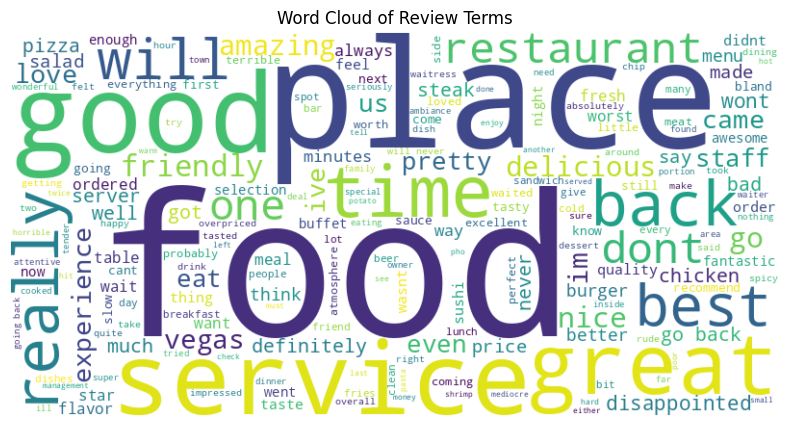


--- Sentiment Breakdown by Topic (%) ---
Sentiment       Negative  Neutral  Positive
Dominant_Topic                             
1                   28.3     22.8      48.9
2                   26.2     23.5      50.2
3                   28.5     27.3      44.2
4                   21.9     21.4      56.6
5                   23.4     24.7      51.9


In [29]:
!pip install wordcloud

import matplotlib.pyplot as plt
from wordcloud import WordCloud
import pandas as pd

print("--- Top 10 Words per Topic ---")
topics = lda_model.print_topics(num_topics=num_topics, num_words=10)
for topic in topics:
    print(f"Topic {topic[0] + 1}: {topic[1]}\n")

dominant_topics = []
for doc in corpus:
    topic_probs = lda_model[doc]
    best_topic = max(topic_probs, key=lambda x: x[1])[0]
    dominant_topics.append(best_topic + 1)

df['Dominant_Topic'] = dominant_topics

print("--- Topic Counts ---")
print(df['Dominant_Topic'].value_counts().sort_index())

all_words = ' '.join(df['Cleaned_Review'])
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(all_words)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Review Terms')
plt.show()

sentiment_by_topic = pd.crosstab(df['Dominant_Topic'], df['Sentiment'], normalize='index') * 100
print("\n--- Sentiment Breakdown by Topic (%) ---")
print(sentiment_by_topic.round(1))

### Reflection:
1. Give each topic a 2-3 word name.  You should list the topic number and a name that you will create that summarize the words used.  For example, "Topic #1 - Slow Service"

### ✍️ Your Response: 🔧
List your topics and names here: Food Quality & Taste, Service & Wait Staff, Order Speed & Time, Menu Options & Pricing, Overall Dining Experience


## 8. Reflect and Recommend

**Business framing:**  
Ultimately, the value of your model comes from how well it can guide business decisions. Use your results to make real-world recommendations.

### Reflection:
1. What business question did your model help answer?
2. What would you recommend to this restaurant to improve customer satisfaction?
3. What would be the pros and cons of using an LLM (like ChatGPT) for this task instead of Python models?
4. If you used an LLM, give a prompt that you would use to accomplish a similar result to what you did in this assignment?  (remember to set the context, specify the output and explain the objectives)


### ✍️ Your Response: 🔧
1. The model helped answer why customers leave positive or negative feedback instead of just knowing if they liked the restaurant. It found the things that helped the business like food quality, wait times, menu options, and service speed that directly influence the customer satisfaction.

2. Improve peak hour service by training staff and manage table turns better to help lower long wait times, which were a major part of negative sentiment. Focus on food consistency by keeping popular items like burgers and sides fresh and consistent, as food quality was a higher driver of positive reviews. Address neutral reviews by paying more attention to customers with normal feedback by checking pricing and portion sizes to easily turn them into common items.

3. Pros: LLMs understand natural language, sarcasm, and slang much better than LDA, and they can summarize topics and give recommendations in plain English without needing a bunch of crazy code.
Cons: LLMs can be expensive at scale, can produce different types of results each time, lack exact mathematical metrics like coherence scores, and they normally have a lot of people questions their privacy.

4. Context: You are a business analyst helping a restaurant owner improve customer satisfaction. Here is the data and here are the rules I would like to follow:
Objective: Analyze the 1,000 customer reviews to determine sentiment them being Positive, Negative, Neutral and group them into 5 main business topics things like Service, Food Quality, Price. For the output: Provide a clean table showing topic frequencies and sentiment percentages per topic, followed by 3 recommendations for management and maybe some backup recommendations in the worst case senario.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_13_text_analytics.ipynb"